In [40]:
%matplotlib inline
import numpy as np
import scipy.integrate as integrate
from scipy.special import airy
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, clear_output
from numpy import cosh

## 2.5
Prove that the given u(t,x) is a solution to the KdV equation.

In [33]:
def u(t,x):
    numerator = -12*(3+4*cosh(2*x-8*t) + cosh(4*x - 64*t))
    denominator = (3*cosh(x-28*t)+ cosh(3*x-36*t))**2
    return numerator/denominator

def u_0(x):
    return u(0,x)

def u_0an(x):
    return -6/cosh(x)**2

In [34]:
x_arr = np.linspace(-10,10,1000)

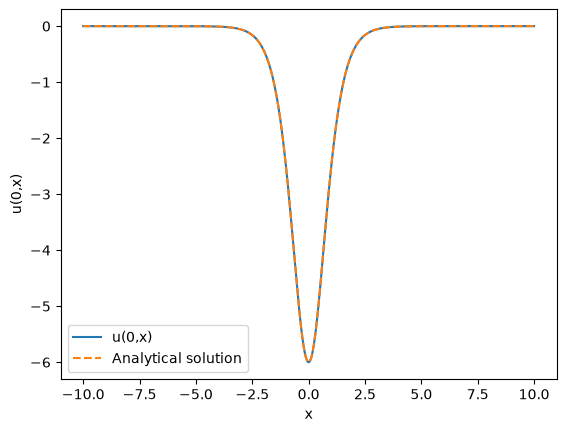

In [35]:
plt.plot(x_arr, u_0(x_arr), label='u(0,x)')
plt.plot(x_arr, u_0an(x_arr), label='Analytical solution', linestyle='dashed')
plt.xlabel('x')
plt.ylabel('u(0,x)')
plt.legend()
plt.show()

### b) Animating the time evolution of u

In [66]:
# --- parameters ---
c = 1.0                 # wave speed
x = np.linspace(-3, 3, 800)  # spatial domain
fig, ax = plt.subplots()
t_0 = -10
line, = ax.plot(x, u(x, t_0), lw=2)
ax.set_ylim(-15, 5)
ax.grid()

# --- update function ---
def update(frame):
    t = (frame / 30)      # controls animation speed
    y = u(x, t_0 +t)
    line.set_ydata(y)
    return line,

plt.close(fig)  # Prevents the static plot from displaying

# --- animate ---
clear_output(wait=True)
ani = FuncAnimation(fig, update, frames=480, interval=30, blit=True);
HTML(ani.to_jshtml())